In [18]:
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error, r2_score
import matplotlib.pyplot as plt

In [19]:
#getting to know the data
aberporth = np.load("aberporth.npy")
cardiff = np.load("cardiff.npy")
valley = np.load("valley.npy")

print(aberporth.shape)
print(cardiff.shape)
print(valley.shape)

print(aberporth)
print(cardiff)
print(valley)

(811, 6)
(556, 6)
(1123, 6)
[[1.957e+03 1.000e+00 8.600e+00 3.900e+00 2.000e+00 8.060e+01]
 [1.957e+03 2.000e+00 8.500e+00 3.200e+00 2.000e+00 8.510e+01]
 [1.957e+03 3.000e+00 1.220e+01 7.400e+00 0.000e+00 8.310e+01]
 ...
 [2.024e+03 5.000e+00 1.550e+01 9.800e+00 0.000e+00 4.820e+01]
 [2.024e+03 6.000e+00 1.550e+01 1.030e+01 0.000e+00 3.360e+01]
 [2.024e+03 7.000e+00 1.740e+01 1.180e+01 0.000e+00 6.900e+01]]
[[1977.     9.    18.3    8.1    0.    48.6]
 [1977.    10.    15.4    9.     0.    76. ]
 [1977.    11.    10.3    4.7    4.   147.9]
 ...
 [2023.    10.    17.4    9.6    0.   178.4]
 [2023.    11.    12.2    5.1    4.   202. ]
 [2023.    12.    10.9    5.7    4.   158.8]]
[[1.930e+03 1.200e+01 8.600e+00 5.500e+00 0.000e+00 1.303e+02]
 [1.931e+03 1.000e+00 8.000e+00 4.200e+00 0.000e+00 6.620e+01]
 [1.931e+03 2.000e+00 7.600e+00 3.700e+00 0.000e+00 6.060e+01]
 ...
 [2.024e+03 5.000e+00 1.700e+01 1.050e+01 0.000e+00 4.480e+01]
 [2.024e+03 6.000e+00 1.680e+01 1.080e+01 0.000e+00 3.0

I will select 3 models to compare. Random Forests, SVM and kNN. I predict random forests will work the best. I picked these 3 because I think they are going to work best with the low number of features - 5. Having random forest also allows us to see how a network technique compares against the other two, and kNN allows us to see how well a computationally cheaper algorithm will compare. SVM is kind of the jack of all trades here I guess. 

In [20]:
#Preparing data
#split into X and Y
aberporthX = aberporth[:, :5]
aberporthY = aberporth[:, -1]

cardiffX = cardiff[:, :5]
cardiffY = cardiff[:, -1]

valleyX = valley[:, :5]
valleyY = valley[:, -1]

print(f"Aberporth: Max: {np.max(aberporthY)} Min: {np.min(aberporthY)}")
print(f"Cardiff: Max: {np.max(cardiffY)} Min: {np.min(cardiffY)}")
print(f"Valley: Max: {np.max(valleyY)} Min: {np.min(valleyY)}")

#Training and testing datasets
aTrainX, aTestX, aTrainY, aTestY = train_test_split(aberporthX, aberporthY, test_size=0.3)
cTrainX, cTestX, cTrainY, cTestY = train_test_split(cardiffX, cardiffY, test_size=0.3)
vTrainX, vTestX, vTrainY, vTestY = train_test_split(valleyX, valleyY, test_size=0.3)

#Scaling data
#KNN and SVM require data scaling since the method of regression behind them rely on distance between data points
#Therefore we will create scaled datasets for these models so that no single feature dominates the decision making
aScaler = StandardScaler()
aTrainXScaled = aScaler.fit_transform(aTrainX)
aTestXScaled = aScaler.transform(aTestX)

cScaler = StandardScaler()
cTrainXScaled = cScaler.fit_transform(cTrainX)
cTestXScaled = cScaler.transform(cTestX)

vScaler = StandardScaler()
vTrainXScaled = vScaler.fit_transform(vTrainX)
vTestXScaled = vScaler.transform(vTestX)

Aberporth: Max: 229.9 Min: 0.0
Cardiff: Max: 267.6 Min: 3.5
Valley: Max: 254.2 Min: 1.3


In [21]:
#KNN regressor
paramGridKnn = {
    "n_neighbors": range(1,51),
    "weights": ['uniform', 'distance'],
}
gridSearchKnn = GridSearchCV(estimator=KNeighborsRegressor(), param_grid=paramGridKnn, cv=5, n_jobs=-1)

#Training for Aberporth
Aknn = GridSearchCV(estimator=KNeighborsRegressor(), param_grid=paramGridKnn, cv=5, n_jobs=-1)
Aknn.fit(aTrainXScaled, aTrainY)

#Training for Cardiff
Cknn = GridSearchCV(estimator=KNeighborsRegressor(), param_grid=paramGridKnn, cv=5, n_jobs=-1)
Cknn.fit(cTrainXScaled, cTrainY)

#Training for Valley
Vknn = GridSearchCV(estimator=KNeighborsRegressor(), param_grid=paramGridKnn, cv=5, n_jobs=-1)
Vknn.fit(vTrainXScaled, vTrainY)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': range(1, 51), 'weights': ['uniform', 'distance']}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information prin

In [22]:
#Random Forest regressor
paramGridRf = {
    "n_estimators": [50,500],
    "criterion": ['squared_error', 'absolute_error', 'poisson'],
    "max_features": ['sqrt', 'log2']
}
gridSearchRf = GridSearchCV(estimator=RandomForestRegressor(), param_grid=paramGridRf, cv=5, n_jobs=-1)

#Training for Aberporth
aRf = GridSearchCV(estimator=RandomForestRegressor(), param_grid=paramGridRf, cv=5, n_jobs=-1)
aRf.fit(aTrainX, aTrainY)

#Training for Cardiff
cRf = GridSearchCV(estimator=RandomForestRegressor(), param_grid=paramGridRf, cv=5, n_jobs=-1)
cRf.fit(cTrainX, cTrainY)

#Training for Valley
vRf = GridSearchCV(estimator=RandomForestRegressor(), param_grid=paramGridRf, cv=5, n_jobs=-1)
vRf.fit(vTrainX, vTrainY)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'absolute_error', ...], 'max_features': ['sqrt', 'log2'], 'n_estimators': [50, 500]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int

In [23]:
#Support Vector Machine Regressor
paramGridSvm = {
    "kernel": ['rbf', 'linear', 'poly', 'sigmoid'],
    "C": [0.01, 10],
    "epsilon": [0.01, 10]
}

#Aberporth
aSvr = GridSearchCV(estimator=SVR(), param_grid=paramGridSvm, cv=5, n_jobs=-1)
aSvr.fit(aTrainXScaled, aTrainY)

#Training for Cardiff
cSvr = GridSearchCV(estimator=SVR(), param_grid=paramGridSvm, cv=5, n_jobs=-1)
cSvr.fit(cTrainXScaled, cTrainY)

#Training for Valley
vSvr = GridSearchCV(estimator=SVR(), param_grid=paramGridSvm, cv=5, n_jobs=-1)
vSvr.fit(vTrainXScaled, vTrainY)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVR()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 10], 'epsilon': [0.01, 10], 'kernel': ['rbf', 'linear', ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed dur

Now all of the models have been trained for every single dataset. SVR and KNN datasets were scaled whereas Random forest wasn't.
It is also worth noting that RF took by far the longest time and data to train/optimise at 50.7s compared to KNN(10.2s) and SVM(1.9s)
There was a similar trend for the data usage as well, although I havent been able to pinpoint exact values atm.

An asterisk to put here is, that could be caused by the fact that the gridsearch in the RF code box simply had more things to run through and therefore took more time and memory. Will need further testing if I want to include it in the poster. 

Next we will predict using the test dataset and calculate which model does the best and by which metric and then come to a conclusion

In [24]:
def getMetrics(preds, true):
    #Obtaining metrics
    MSE = []
    MAE = []
    RMSE = []
    MAPE = []
    R2 = []

    for pred in preds:
        MSE.append(mean_squared_error(true, pred))
        MAE.append(mean_absolute_error(true, pred))
        RMSE.append(root_mean_squared_error(true, pred))
        MAPE.append(mean_absolute_percentage_error(true, pred))
        R2.append(r2_score(true, pred))

    return MSE, MAE, RMSE, MAPE, R2

In [25]:
#Aberporth
aKnnPred = Aknn.best_estimator_.predict(aTestXScaled)
aRfPred = aRf.best_estimator_.predict(aTestX)
aSvrPred = aSvr.best_estimator_.predict(aTestXScaled)
aPreds = [aKnnPred, aRfPred, aSvrPred]
aMSE, aMAE, aRMSE, aMAPE, aR2 = getMetrics(aPreds, aTestY)

#Cardiff
cKnnPred = Cknn.best_estimator_.predict(cTestXScaled)
cRfPred = cRf.best_estimator_.predict(cTestX)
cSvrPred = cSvr.best_estimator_.predict(cTestXScaled)
cPreds = [cKnnPred, cRfPred, cSvrPred]
cMSE, cMAE, cRMSE, cMAPE, cR2 = getMetrics(cPreds, cTestY)

#Valley
vKnnPred = Vknn.best_estimator_.predict(vTestXScaled)
vRfPred = vRf.best_estimator_.predict(vTestX)
vSvrPred = vSvr.best_estimator_.predict(vTestXScaled)
vPreds = [vKnnPred, vRfPred, vSvrPred]
vMSE, vMAE, vRMSE, vMAPE, vR2 = getMetrics(vPreds, vTestY)

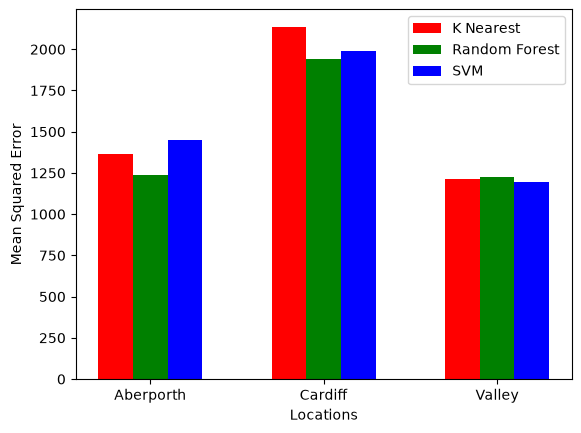

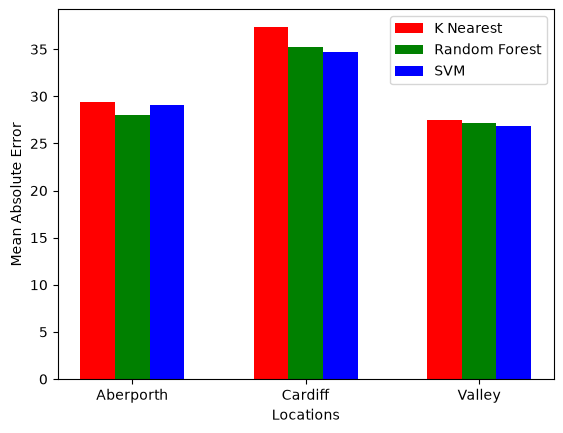

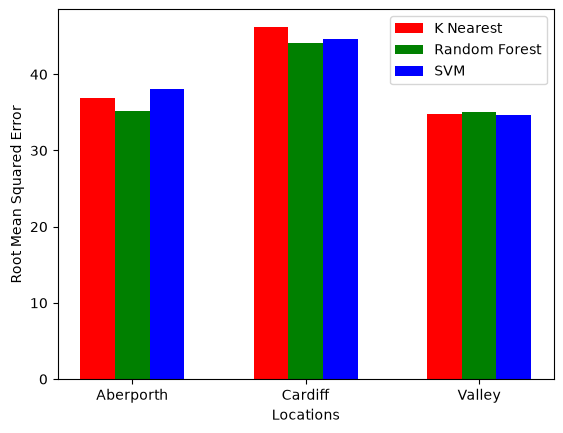

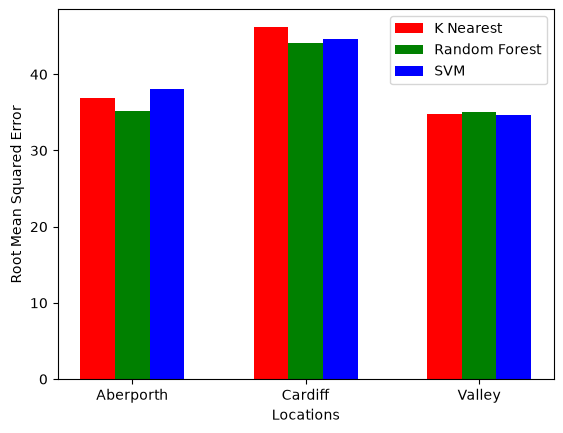

[0.8865891866427263, 0.9113476764159301, 0.7293215235384867]
[0.5088139759287389, 0.4539374133043732, 0.4257619701869394]
[0.6860083997947881, 0.6413114377315706, 0.6302874541323397]


In [26]:
#Bar plots
#MSE
x = np.arange(3)
knnMSE = [aMSE[0], cMSE[0], vMSE[0]]
rfMSE = [aMSE[1], cMSE[1], vMSE[1]]
svrMSE = [aMSE[2], cMSE[2], vMSE[2]]
width = 0.2
plt.bar(x-width, knnMSE, width, color='red')
plt.bar(x, rfMSE, width, color='green')
plt.bar(x+width, svrMSE, width, color='blue')
plt.xticks(x,['Aberporth', 'Cardiff', 'Valley'])
plt.xlabel("Locations")
plt.ylabel("Mean Squared Error")
plt.legend(['K Nearest', 'Random Forest', 'SVM'])
plt.show()

#MAE
x = np.arange(3)
knnMAE = [aMAE[0], cMAE[0], vMAE[0]]
rfMAE = [aMAE[1], cMAE[1], vMAE[1]]
svrMAE = [aMAE[2], cMAE[2], vMAE[2]]
width = 0.2
plt.bar(x-width, knnMAE, width, color='red')
plt.bar(x, rfMAE, width, color='green')
plt.bar(x+width, svrMAE, width, color='blue')
plt.xticks(x,['Aberporth', 'Cardiff', 'Valley'])
plt.xlabel("Locations")
plt.ylabel("Mean Absolute Error")
plt.legend(['K Nearest', 'Random Forest', 'SVM'])
plt.show()

#RMSE
x = np.arange(3)
knnRMSE = [aRMSE[0], cRMSE[0], vRMSE[0]]
rfRMSE = [aRMSE[1], cRMSE[1], vRMSE[1]]
svrRMSE = [aRMSE[2], cRMSE[2], vRMSE[2]]
width = 0.2
plt.bar(x-width, knnRMSE, width, color='red')
plt.bar(x, rfRMSE, width, color='green')
plt.bar(x+width, svrRMSE, width, color='blue')
plt.xticks(x,['Aberporth', 'Cardiff', 'Valley'])
plt.xlabel("Locations")
plt.ylabel("Root Mean Squared Error")
plt.legend(['K Nearest', 'Random Forest', 'SVM'])
plt.show()

#R2
knnR2 = [aR2[0], cR2[0], vR2[0]]
rfR2 = [aR2[1], cR2[1], vR2[1]]
svrR2 = [aR2[2], cR2[2], vR2[2]]
width = 0.2
plt.bar(x-width, knnRMSE, width, color='red')
plt.bar(x, rfRMSE, width, color='green')
plt.bar(x+width, svrRMSE, width, color='blue')
plt.xticks(x,['Aberporth', 'Cardiff', 'Valley'])
plt.xlabel("Locations")
plt.ylabel("Root Mean Squared Error")
plt.legend(['K Nearest', 'Random Forest', 'SVM'])
plt.show()

print(aMAPE)
print(cMAPE)
print(vMAPE)